/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


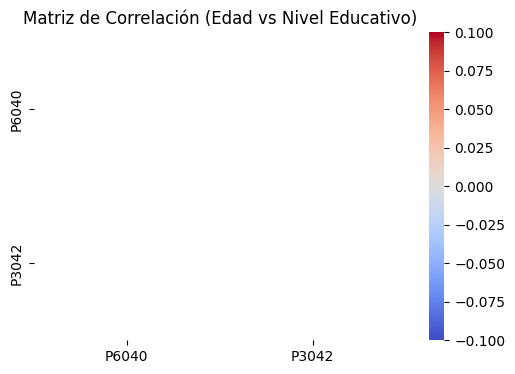


--- Iniciando Batería de Modelos (Corregida) ---
Entrenando 0. Línea Base (Dummy)...
Entrenando 1. Regresión Logística...
Entrenando 2. Random Forest...
Entrenando 3. XGBoost...

--- RESULTADOS FINALES (SIN FUGA DE INFORMACIÓN) ---


,Modelo,F1-macro (Media),F1-macro (DE),AUC-ROC,Tiempo (s)
0,0. Línea Base (Dummy),0.4891,0.0000,0.5000,1.99
1,1. Regresión Logística,0.5117,0.0036,0.6563,0.64
2,2. Random Forest,0.5532,0.0043,0.7155,11.64
3,3. XGBoost,0.5471,0.0035,0.7194,2.82


/tmp/ipykernel_550/2347848093.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='F1-macro (Media)', data=df_resultados, palette='viridis')


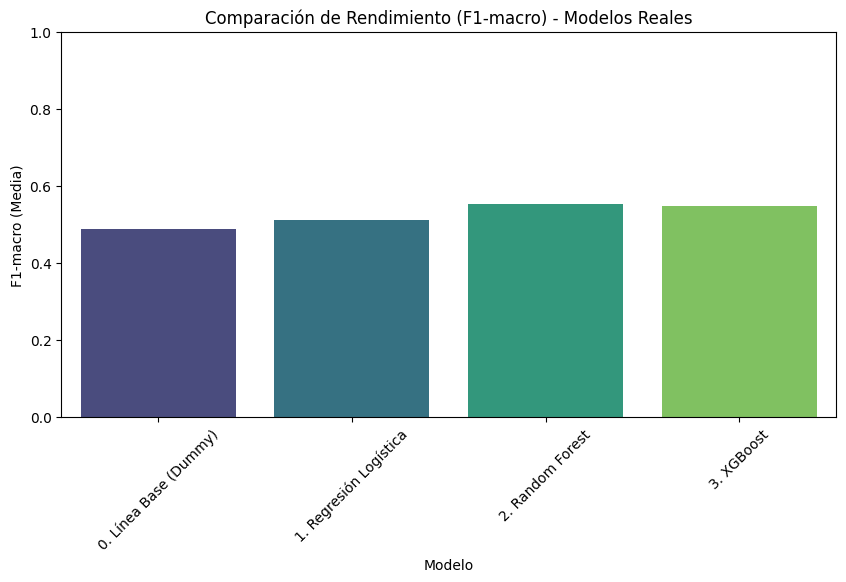

In [9]:
# @title EDA y Modelado Predictivo: Desempleo en Pasto (2022-2025)
!pip install xgboost statsmodels -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, make_scorer, classification_report
import time
import warnings
warnings.filterwarnings('ignore')

# 1. CARGA DE DATOS
print("--- 1. CARGANDO DATOS ---")
df = pd.read_csv('/content/Pasto_dataset_consolidado.csv')
print(f"✅ Datos cargados: {len(df)} registros.\n")

# Crear variable objetivo (Desempleado: 1 si DSI=1 o OCI=1)
if 'DSI' in df.columns:
    df['Desempleado'] = df['DSI'].apply(lambda x: 1 if x == 1 else 0)
else:
    df['Desempleado'] = df['OCI'].apply(lambda x: 1 if x == 1 else 0)

# Mapeos para gráficos
df['Sexo'] = df['P3271'].map({1: 'Hombre', 2: 'Mujer'})
df['Edad'] = pd.to_numeric(df['P6040'], errors='coerce')

# 2. ANÁLISIS EXPLORATORIO (EDA)
print("--- 2. GENERANDO GRÁFICOS EDA ---")

# --- 2.1 Univariado: Distribución del Desempleo ---
plt.figure(figsize=(6,4))
sns.countplot(x='Desempleado', data=df, palette='Set2')
plt.title('Distribución de la Población por Condición de Desempleo (Pasto)')
plt.ylabel('Cantidad de Personas')
plt.xlabel('0 = Ocupado, 1 = Desempleado')
plt.savefig('fig_01_univariado_desempleo.png', bbox_inches='tight')
plt.show()

# --- 2.2 Bivariado: Desempleo por Sexo ---
tasa_sexo = df.groupby('Sexo')['Desempleado'].mean().reset_index()
plt.figure(figsize=(6,4))
sns.barplot(x='Sexo', y='Desempleado', data=tasa_sexo, palette='Blues_d')
plt.title('Tasa de Desempleo por Sexo en Pasto (2022-2025)')
plt.ylabel('Proporción de Desempleo')
plt.savefig('fig_02_bivariado_sexo.png', bbox_inches='tight')
plt.show()

# --- 2.3 Bivariado: Edad vs Desempleo (Boxplot) ---
plt.figure(figsize=(8,5))
sns.boxplot(x='Desempleado', y='Edad', data=df, palette='Set2')
plt.title('Distribución de la Edad según Condición de Desempleo')
plt.xlabel('0 = Ocupado, 1 = Desempleado')
plt.ylabel('Edad')
plt.savefig('fig_03_eda_edad.png', bbox_inches='tight')
plt.show()

# --- 2.4 Bivariado: Desempleo por Grupo Etario ---
def categorizar_edad(edad):
    if pd.isna(edad): return 'Desconocido'
    if 14 <= edad <= 28: return '1. Jóvenes (14-28)'
    elif 29 <= edad <= 59: return '2. Adultos (29-59)'
    elif edad >= 60: return '3. Adultos Mayores (60+)'
    else: return '0. Niños/Menores'

df['Grupo_Etario'] = df['Edad'].apply(categorizar_edad)
df_edad = df[df['Grupo_Etario'].isin(['1. Jóvenes (14-28)', '2. Adultos (29-59)', '3. Adultos Mayores (60+)'])].copy()
tasa_edad = df_edad.groupby('Grupo_Etario')['Desempleado'].mean().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(x='Grupo_Etario', y='Desempleado', data=tasa_edad, palette='Oranges_d')
plt.title('Tasa de Desempleo por Grupo Etario en Pasto (2022-2025)')
plt.ylabel('Proporción de Desempleo')
plt.xlabel('Grupo de Edad')
plt.savefig('fig_04_eda_grupo_etario.png', bbox_inches='tight')
plt.show()

# --- 2.5 Multivariado: Correlación y VIF ---
cols_num = ['Edad', 'P3042', 'INGLABO', 'P6800']
cols_num = [c for c in cols_num if c in df.columns]
df_vif = df[cols_num].apply(pd.to_numeric, errors='coerce')
df_vif = df_vif.fillna(df_vif.median()) # Rellenar nulos con la mediana

plt.figure(figsize=(8,6))
sns.heatmap(df_vif.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación (Variables Predictoras Numéricas)')
plt.savefig('fig_05_multivariado_correlacion.png', bbox_inches='tight')
plt.show()

X_vif = add_constant(df_vif)
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print("\n--- Factor de Inflación de la Varianza (VIF) ---")
print(vif_data[vif_data['Variable'] != 'const'].to_string(index=False))
print("\n")

# 3. MODELADO PREDICTIVO (SIN FUGA)
print("--- 3. BATERÍA DE MODELOS ---")
# Usamos solo variables predictivas para evitar Data Leakage
cols_predictoras = ['P3271', 'P6040', 'P3042', 'CLASE', 'AREA']
cols_predictoras = [c for c in cols_predictoras if c in df.columns]

X = df[cols_predictoras].copy().fillna(-1)
y = df['Desempleado']

# Partición 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocesamiento
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Modelos
models = {
    '0. Línea Base (Dummy)': DummyClassifier(strategy='most_frequent'),
    '1. Regresión Logística': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    '2. Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42, n_jobs=-1),
    '3. XGBoost': XGBClassifier(scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(), random_state=42, eval_metric='logloss', n_jobs=-1)
}

# Validación Cruzada Repetida 5x2
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
scoring = {'f1_macro': make_scorer(f1_score, average='macro'), 'roc_auc': 'roc_auc'}

resultados = []
for nombre, modelo in models.items():
    print(f"Entrenando {nombre}...")
    start_time = time.time()
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', modelo)])
    cv_results = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    f1_mean = cv_results['test_f1_macro'].mean()
    f1_std = cv_results['test_f1_macro'].std()
    auc_mean = cv_results['test_roc_auc'].mean()
    tiempo = time.time() - start_time

    resultados.append({
        'Modelo': nombre,
        'F1-macro (Media)': round(f1_mean, 4),
        'F1-macro (DE)': round(f1_std, 4),
        'AUC-ROC': round(auc_mean, 4),
        'Tiempo (s)': round(tiempo, 2)
    })

df_resultados = pd.DataFrame(resultados)
print("\n--- RESULTADOS DE LA BATERÍA DE MODELOS ---")
display(df_resultados)
df_resultados.to_csv('resultados_modelos_bateria.csv', index=False)

plt.figure(figsize=(10,5))
sns.barplot(x='Modelo', y='F1-macro (Media)', data=df_resultados, palette='viridis')
plt.title('Comparación de Rendimiento (F1-macro) por Modelo')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.savefig('fig_06_comparacion_modelos.png', bbox_inches='tight')
plt.show()

# 4. OPTIMIZACIÓN DE HIPERPARÁMETROS (GridSearchCV)
print("\n--- 4. OPTIMIZACIÓN CON GRIDSEARCHCV (Random Forest) ---")
param_grid_rf = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]
}

pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))])

grid_search = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='f1_macro', n_jobs=-1)
start_time = time.time()
grid_search.fit(X_train, y_train)
tiempo_grid = time.time() - start_time

print(f"Mejores hiperparámetros: {grid_search.best_params_}")
print(f"Mejor F1-macro en validación: {grid_search.best_score_:.4f}")
print(f"Tiempo de optimización: {tiempo_grid:.2f} segundos")

y_pred_test = grid_search.predict(X_test)
f1_test = f1_score(y_test, y_pred_test, average='macro')
print(f"\nF1-macro en el conjunto de PRUEBA (sin fuga): {f1_test:.4f}")

print("\n✅ PROCESO COMPLETO TERMINADO. Por favor, descarga las imágenes y los archivos CSV generados.")

/tmp/ipykernel_550/1300570137.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Desempleado', y='P6040', data=df, palette='Set2')


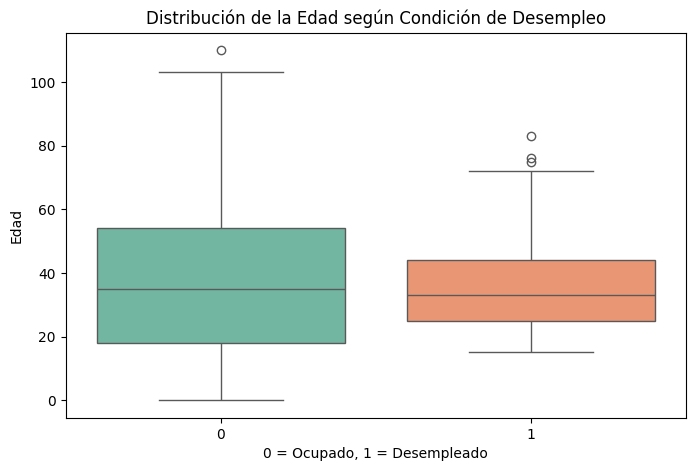

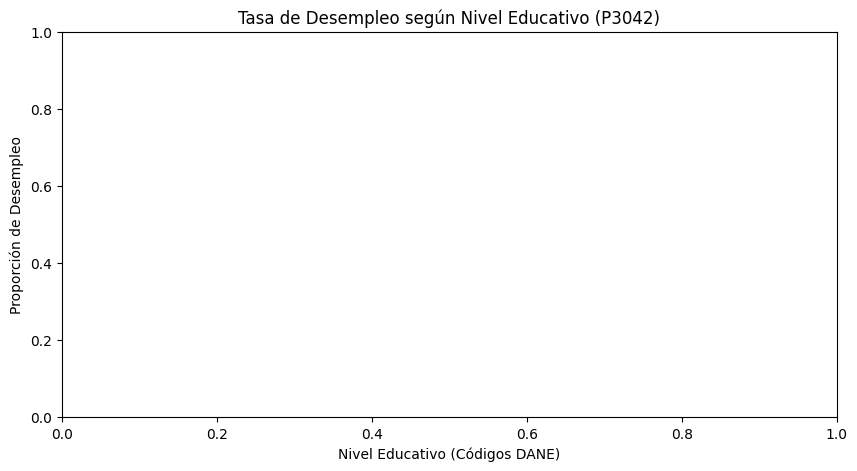

In [10]:
# Generar gráficos EDA con mayor valor de negocio
plt.figure(figsize=(8,5))
sns.boxplot(x='Desempleado', y='P6040', data=df, palette='Set2')
plt.title('Distribución de la Edad según Condición de Desempleo')
plt.xlabel('0 = Ocupado, 1 = Desempleado')
plt.ylabel('Edad')
plt.savefig('fig_eda_edad.png', bbox_inches='tight')
plt.show()

# Tasa de desempleo por nivel educativo (P3042)
tasa_edu = df.groupby('P3042')['Desempleado'].mean().reset_index()
plt.figure(figsize=(10,5))
sns.barplot(x='P3042', y='Desempleado', data=tasa_edu, palette='Blues_d')
plt.title('Tasa de Desempleo según Nivel Educativo (P3042)')
plt.ylabel('Proporción de Desempleo')
plt.xlabel('Nivel Educativo (Códigos DANE)')
plt.savefig('fig_eda_educacion.png', bbox_inches='tight')
plt.show()

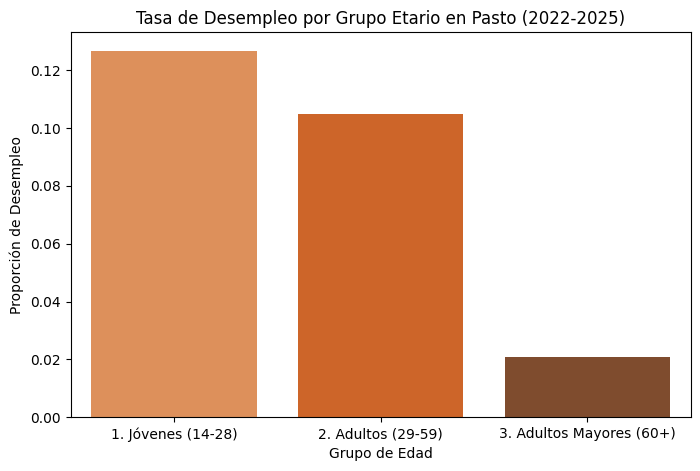

✅ Gráfico generado con éxito. Descárgalo como fig_eda_grupo_etario.png


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Asegurar que la edad sea numérica
df['Edad'] = pd.to_numeric(df['P6040'], errors='coerce')

# 2. Crear categorías de edad (basadas en la legislación laboral colombiana)
def categorizar_edad(edad):
    if pd.isna(edad): return 'Desconocido'
    if 14 <= edad <= 28: return '1. Jóvenes (14-28)'
    elif 29 <= edad <= 59: return '2. Adultos (29-59)'
    elif edad >= 60: return '3. Adultos Mayores (60+)'
    else: return '0. Niños/Menores'

df['Grupo_Etario'] = df['Edad'].apply(categorizar_edad)

# 3. Filtrar solo población en edad de trabajar (PET)
df_edad = df[df['Grupo_Etario'].isin(['1. Jóvenes (14-28)', '2. Adultos (29-59)', '3. Adultos Mayores (60+)'])].copy()

# 4. Calcular la tasa de desempleo por grupo
tasa_edad = df_edad.groupby('Grupo_Etario')['Desempleado'].mean().reset_index()

# 5. Graficar
plt.figure(figsize=(8,5))
sns.barplot(
    x='Grupo_Etario',
    y='Desempleado',
    data=tasa_edad,
    palette='Oranges_d',
    hue='Grupo_Etario',
    legend=False
)
plt.title('Tasa de Desempleo por Grupo Etario en Pasto (2022-2025)')
plt.ylabel('Proporción de Desempleo')
plt.xlabel('Grupo de Edad')
plt.savefig('fig_eda_grupo_etario.png', bbox_inches='tight')
plt.show()
print("✅ Gráfico generado con éxito. Descárgalo como fig_eda_grupo_etario.png")

In [15]:
from sklearn.model_selection import GridSearchCV
import time

print("--- OPTIMIZACIÓN DE HIPERPARÁMETROS (GridSearchCV) ---")

# Definimos el espacio de búsqueda para el mejor modelo (Random Forest)
param_grid_rf = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]
}

# Creamos el pipeline base para RF
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))])

# Búsqueda
grid_search = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='f1_macro', n_jobs=-1)
start_time = time.time()
grid_search.fit(X_train, y_train)
tiempo_grid = time.time() - start_time

print(f"Mejores hiperparámetros encontrados: {grid_search.best_params_}")
print(f"Mejor F1-macro en validación: {grid_search.best_score_:.4f}")
print(f"Tiempo de optimización: {tiempo_grid:.2f} segundos")

# Evaluar en el conjunto de prueba (Test) que habíamos guardado
from sklearn.metrics import classification_report, f1_score
y_pred_test = grid_search.predict(X_test)
f1_test = f1_score(y_test, y_pred_test, average='macro')
print(f"F1-macro en el conjunto de PRUEBA (sin fuga): {f1_test:.4f}")

--- OPTIMIZACIÓN DE HIPERPARÁMETROS (GridSearchCV) ---
Mejores hiperparámetros encontrados: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}
Mejor F1-macro en validación: 0.5516
Tiempo de optimización: 29.57 segundos
F1-macro en el conjunto de PRUEBA (sin fuga): 0.5538
